# Measuring one shared move

A positive pair value means two stocks often rise and fall together. Compare the two periods, then read the fraction of total variation captured by the leading component.

This is a seeded teaching example. Dates are illustrative.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from panic_detector.features.returns import daily_log_returns

rng = np.random.default_rng(2020)
dates = pd.bdate_range("2019-01-02", periods=320)
common = rng.normal(size=(320, 1))
strength = np.where(np.arange(320)[:, None] < 200, 0.18, 1.6)
moves = 0.009 * (rng.normal(size=(320, 8)) + strength * common)
prices = pd.DataFrame(100 * np.exp(moves.cumsum(axis=0)), index=dates, columns=list("ABCDEFGH"))
returns = daily_log_returns(prices)

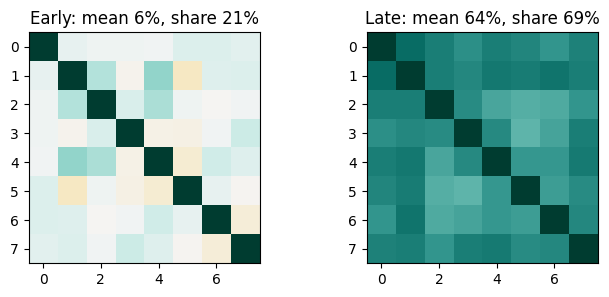

In [2]:
from panic_detector.features.rolling_corr import correlation_matrix, average_correlation
from panic_detector.models.eigen import top_eigenvalue
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, sample, title in zip(axes, (returns.iloc[:60], returns.iloc[-60:]), ("Early", "Late")):
    matrix = correlation_matrix(sample)
    ax.imshow(matrix, vmin=-1, vmax=1, cmap="BrBG")
    share = top_eigenvalue(matrix.to_numpy()) / len(matrix)
    ax.set_title(f"{title}: mean {average_correlation(matrix):.0%}, share {share:.0%}")
display(fig); plt.close(fig)